# CS01 - Solving the AC load flow with Newton-Raphson (from scratch, then with PyPSA)

**Problem type:** state estimation of a meshed AC grid - "given what is produced and
consumed, what are the voltages, the flows and the losses?"
**Source:** Exercise 5, Assignment 2.

## 1. Context
Three buses, three identical lines (pi model). Bus 1 is the **slack** (balance) bus,
bus 2 a **PV** generator bus, bus 3 a **PQ** load bus.

| Known | Unknown |
|---|---|
| line series admittance, line shunt admittance | $\theta_2$, $\theta_3$, $|U_3|$ |
| $\theta_1 = 0^\circ$, $|U_1| = 1.00$ | $P_{G1}$, $Q_{G1}$, $Q_{G2}$ |
| $|U_2| = 1.05$, $P_{G2} = 0.50$ | line flows $S_{ik}$, line losses $S_{ik,v}$ |
| $P_{D3} = 2.50$, $Q_{D3} = 1.00$ (p.u., $S_b = 100$ MVA) | total losses $S_{v,ges}$ |

## 2. Exercise
1. Determine the node admittance matrix $\mathbf{Y}$.
2. Derive the load-flow problem and solve it with Newton-Raphson.
3. Determine the power flows and the transmission losses.
4. *(Expert)* Validate the result with PyPSA and discuss the line data.

## 3. A note on the line data (read this first)
The table of the exercise gives $\underline{Y}_{ik} = j0.1$ and $\underline{Y}^0_{ik} = -j8$.
Read literally this is not physical: a series admittance $+j0.1$ is a capacitor of
$-j10$ p.u. in series, and a shunt of $-j8$ is an 8 p.u. reactor. Both values are
plausible once the two rows are swapped:

* **Interpretation A (used here):** series admittance $\underline{Y}_{ik} = -j8$
  (series reactance $X = 0.125$ p.u.), total line charging $\underline{Y}^0_{ik} = +j0.1$,
  i.e. $j0.05$ at each end of the pi model.
* **Interpretation B (sensitivity):** the two values are impedances: $Z_{ik} = j0.1$
  ($Y = -j10$) and a shunt reactance of $-j8$ ($Y^0 = +j0.125$).

Both give the same physics ($B \cdot X$ is identical), and section 9 shows that the results
differ only moderately. The literal reading makes the problem **infeasible**
(section 9 proves it numerically).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs.newton import make_ybus, nr_load_flow, branch_flows
from pscs.plotting import SERIES, CRITICAL, INK2, save, limit_line

DATA, FIG, TAB = pscs.setup()
np.set_printoptions(precision=4, suppress=True)

## 4. Step 1 - Node admittance matrix
Each line $i$-$k$ adds $\underline{y}_{ik} + \underline{Y}^0_{ik}/2$ to the diagonal terms
$Y_{ii}$ and $Y_{kk}$, and $-\underline{y}_{ik}$ to the off-diagonal terms. With three
identical lines every bus sees two lines:
$$Y_{ii} = 2(-j8) + 2(j0.05) = -j15.9, \qquad Y_{ik} = +j8 .$$

In [2]:
Y_SERIES, Y_SHUNT = -8j, 0.1j                     # interpretation A, p.u.
pairs = [(0, 1), (0, 2), (1, 2)]
names = ["1-2", "1-3", "2-3"]
branches = [dict(f=i, t=k, y=Y_SERIES, ysh=Y_SHUNT) for i, k in pairs]
Y = make_ybus(3, branches)
pd.DataFrame(Y, index=["1", "2", "3"], columns=["1", "2", "3"])

,1,2,3
1,0.0-15.9j,0.0+ 8.0j,0.0+ 8.0j
2,0.0+ 8.0j,0.0-15.9j,0.0+ 8.0j
3,0.0+ 8.0j,0.0+ 8.0j,0.0-15.9j


## 5. Step 2 - The load-flow problem
The lines are lossless ($G = 0$), so the power-flow equations reduce to
$$P_i = \sum_k |U_i||U_k| B_{ik}\sin(\theta_i-\theta_k), \qquad
  Q_i = -\sum_k |U_i||U_k| B_{ik}\cos(\theta_i-\theta_k).$$
Unknown vector $x = [\theta_2, \theta_3, |U_3|]$. Equations (specified = computed):
$$\begin{aligned}
P_2 &= 8|U_2||U_1|\sin\theta_{21} + 8|U_2||U_3|\sin\theta_{23} = +0.50\\
P_3 &= 8|U_3||U_1|\sin\theta_{31} + 8|U_3||U_2|\sin\theta_{32} = -2.50\\
Q_3 &= 15.9|U_3|^2 - 8|U_3||U_1|\cos\theta_{31} - 8|U_3||U_2|\cos\theta_{32} = -1.00
\end{aligned}$$
There is **no $Q_2$ equation**: bus 2 is a PV bus, its voltage is fixed and $Q_{G2}$ is
whatever is needed. Newton-Raphson solves
$\mathbf{J}\,[\Delta\theta_2, \Delta\theta_3, \Delta|U_3|]^T = [\Delta P_2, \Delta P_3, \Delta Q_3]^T$
from a **flat start** ($\theta = 0$, $|U_3| = 1$).

In [3]:
bus_type = np.array(["slack", "PV", "PQ"])
P_spec = np.array([0.0, 0.50, -2.50])
Q_spec = np.array([0.0, 0.0, -1.00])
V0 = np.array([1.00, 1.05, 1.00])
res = nr_load_flow(Y, bus_type, P_spec, Q_spec, V0, np.zeros(3))
print("Jacobian at the flat start (rows dP2, dP3, dQ3; columns dtheta2, dtheta3, d|U3|):")
print(res["J0"])
res["log"].to_csv(TAB / "cs01_nr_iterations.csv")
res["log"]

Jacobian at the flat start (rows dP2, dP3, dQ3; columns dtheta2, dtheta3, d|U3|):
[[16.8 -8.4  0. ]
 [-8.4 16.4  0. ]
 [ 0.   0.  15.4]]


,max |mismatch| (p.u.),theta_2 (deg),theta_3 (deg),|V_3| (p.u.)
iteration,,,,
0,2.5000e+00,0.0000,0.0000,1.0000
1,2.0841e-01,-3.5782,-10.5668,0.9675
2,4.1325e-03,-3.6522,-11.0830,0.9518
3,1.8546e-06,-3.6530,-11.0949,0.9515
4,3.9058e-13,-3.6530,-11.0949,0.9515


The maximum mismatch drops from 2.5 to below $10^{-10}$ in **4 iterations**, and the
number of correct digits roughly doubles at each step: quadratic convergence, as in CS00.

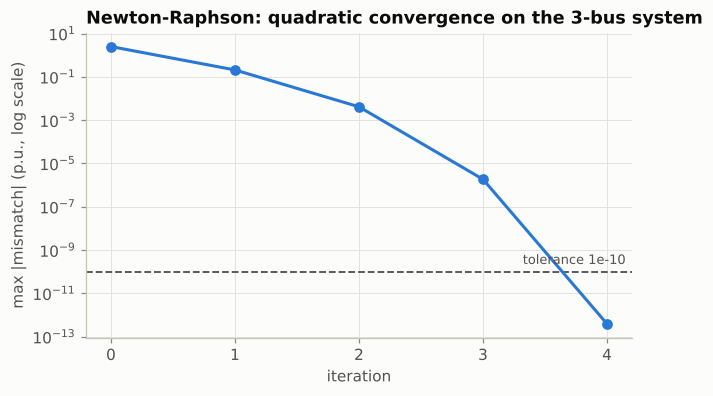

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
log = res["log"]
ax.semilogy(log.index, log["max |mismatch| (p.u.)"], "o-", color=SERIES[0])
limit_line(ax, 1e-10, "tolerance 1e-10", color=INK2)
ax.set_xlabel("iteration"); ax.set_ylabel("max |mismatch| (p.u., log scale)")
ax.set_title("Newton-Raphson: quadratic convergence on the 3-bus system")
ax.set_xticks(log.index)
save(fig, FIG / "cs01_convergence.png")
fig

## 6. Step 3 - Results: voltages, generation, flows and losses

In [5]:
V, th = res["V"], res["th"]
S_inj = res["P"] + 1j * res["Q"]
gen = pd.Series({"P_G1": S_inj[0].real, "Q_G1": S_inj[0].imag,
                 "Q_G2": S_inj[1].imag})          # bus 2 injection = G2 (no load at bus 2)
buses = pd.DataFrame({"|U| (p.u.)": V, "theta (deg)": np.degrees(th)}, index=["1", "2", "3"])
flows = branch_flows(branches, V, th, names)
total_loss = flows[["P_loss", "Q_loss"]].sum()
display_flows = flows.copy()
display_flows.columns = ["P_ik", "Q_ik", "P_ki", "Q_ki", "P_ik,v (loss)", "Q_ik,v (loss)"]
print(buses.round(5)); print(); print(gen.round(5)); print()
print("Total losses S_v,ges = %.5f + j%.5f p.u." % (total_loss.P_loss, total_loss.Q_loss))
display_flows.round(5)

   |U| (p.u.)  theta (deg)
1      1.0000       0.0000
2      1.0500      -3.6530
3      0.9515     -11.0949

P_G1    2.0000
Q_G1    0.0474
Q_G2    1.2216
dtype: float64

Total losses S_v,ges = 0.00000 + j0.26899 p.u.


,P_ik,Q_ik,P_ki,Q_ki,"P_ik,v (loss)","Q_ik,v (loss)"
branch,,,,,,
1-2,0.5352,-0.4329,-0.5352,0.3819,0.0,-0.0510
1-3,1.4648,0.4803,-1.4648,-0.2722,0.0,0.2081
2-3,1.0352,0.8397,-1.0352,-0.7278,0.0,0.1119


**Reading the results**
* $|U_3| = 0.951$ p.u. at $\theta_3 = -11.1^\circ$ ($\theta_2 = -3.65^\circ$): the load bus
  sits just above the usual lower limit of 0.95 p.u.
* $P_{G1} = 2.000$ p.u.: the lines are lossless, so the slack supplies exactly
  $2.50 - 0.50$. **Active losses are zero**; only reactive power is "lost".
* The **reactive balance** is $Q_{G1} + Q_{G2} - Q_{D3} = Q_{v,ges}$: series reactances
  consume reactive power ($I^2X$), the line capacitances produce some ($|U|^2B/2$ at each end).
  With heavy flows, consumption dominates.
* Line 1-3 carries most of the load; bus 2 (at 1.05 p.u.) also feeds bus 3.

## 7. Validation with PyPSA
The same network is stored as a PyPSA dataset (`data/networks/ex5_3bus`, 110 kV and 100 MVA
bases). PyPSA works in MW / MVAr and ohm / siemens; we divide by $S_b = 100$ MVA to compare.

In [6]:
n = pypsa.Network(DATA / "networks" / "ex5_3bus")
print(n.lines[["bus0", "bus1", "r", "x", "b"]])
n.pf()
cmp = pd.DataFrame({
    "own NR": [V[2], np.degrees(th[1]), np.degrees(th[2]), gen.P_G1, gen.Q_G1, gen.Q_G2, total_loss.Q_loss],
    "PyPSA": [n.buses_t.v_mag_pu.iloc[0]["3"], np.degrees(n.buses_t.v_ang.iloc[0]["2"]),
              np.degrees(n.buses_t.v_ang.iloc[0]["3"]), n.generators_t.p.iloc[0]["G1"] / 100,
              n.generators_t.q.iloc[0]["G1"] / 100, n.generators_t.q.iloc[0]["G2"] / 100,
              (n.lines_t.q0.iloc[0] + n.lines_t.q1.iloc[0]).sum() / 100]},
    index=["|U3| (p.u.)", "theta2 (deg)", "theta3 (deg)", "P_G1 (p.u.)", "Q_G1 (p.u.)",
           "Q_G2 (p.u.)", "Q losses (p.u.)"])
cmp["difference"] = cmp["PyPSA"] - cmp["own NR"]
cmp.to_csv(TAB / "cs01_validation.csv")
cmp.round(6)

     bus0 bus1    r       x       b
name                               
L1-2    1    2  0.0  15.125  0.0008
L1-3    1    3  0.0  15.125  0.0008
L2-3    2    3  0.0  15.125  0.0008


,own NR,PyPSA,difference
|U3| (p.u.),0.9515,0.9515,0.0
theta2 (deg),-3.6530,-3.6530,0.0
theta3 (deg),-11.0949,-11.0949,0.0
P_G1 (p.u.),2.0000,2.0000,-0.0
Q_G1 (p.u.),0.0474,0.0474,-0.0
Q_G2 (p.u.),1.2216,1.2216,-0.0
Q losses (p.u.),0.2690,0.2690,-0.0


Our 60-line Newton-Raphson and PyPSA agree to machine precision. In real projects this
check (a hand-built model against a trusted tool, or two tools against each other) is the
first step of any study: it catches unit errors, which are the most frequent mistakes.

## 8. Voltage at the load bus versus load (why 0.95 p.u. matters)

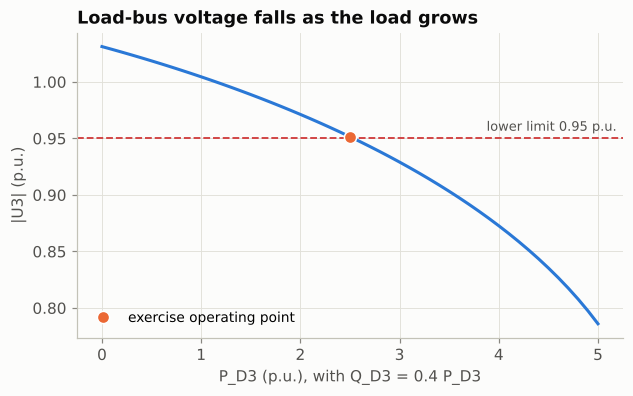

In [7]:
loads = np.linspace(0.0, 5.0, 51)
v3 = []
for pd3 in loads:
    r = nr_load_flow(Y, bus_type, np.array([0, 0.5, -pd3]), np.array([0, 0, -pd3 * 0.4]),
                     V0, np.zeros(3), max_iter=30)
    v3.append(r["V"][2] if r["converged"] else np.nan)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(loads, v3, color=SERIES[0])
ax.plot([2.5], [V[2]], "o", color=SERIES[1], ms=8, markeredgecolor="white", label="exercise operating point")
limit_line(ax, 0.95, "lower limit 0.95 p.u.", color=CRITICAL)
ax.set_xlabel("P_D3 (p.u.), with Q_D3 = 0.4 P_D3"); ax.set_ylabel("|U3| (p.u.)")
ax.set_title("Load-bus voltage falls as the load grows")
ax.legend(loc="lower left")
save(fig, FIG / "cs01_v3_vs_load.png")
fig

## 9. Sensitivity to the line data (interpretations B and literal)

In [8]:
def solve(y, ysh):
    br = [dict(f=i, t=k, y=y, ysh=ysh) for i, k in pairs]
    try:
        r = nr_load_flow(make_ybus(3, br), bus_type, P_spec, Q_spec, V0, np.zeros(3), max_iter=30)
    except np.linalg.LinAlgError:
        return {"converged": False}
    if not r["converged"]:
        return {"converged": False, "|U3|": np.nan, "theta3 (deg)": np.nan, "Q_G1": np.nan, "Q_G2": np.nan}
    return {"converged": True, "|U3|": r["V"][2], "theta3 (deg)": np.degrees(r["th"][2]),
            "Q_G1": r["Q"][0], "Q_G2": r["Q"][1]}

sens = pd.DataFrame({
    "A: Y=-j8, Y0=j0.1 (used)": solve(-8j, 0.1j),
    "B: Z=j0.1, Z0=-j8": solve(1 / 0.1j, 1 / -8j),
    "literal: Y=j0.1, Y0=-j8": solve(0.1j, -8j),
}).T
sens.to_csv(TAB / "cs01_sensitivity.csv")
sens

,converged,|U3|,theta3 (deg),Q_G1,Q_G2
"A: Y=-j8, Y0=j0.1 (used)",True,0.9515,-11.0949,0.0474,1.2216
"B: Z=j0.1, Z0=-j8",True,0.9711,-8.7008,-0.2112,1.2809
"literal: Y=j0.1, Y0=-j8",False,NaN,NaN,NaN,NaN


* Interpretations A and B give $|U_3|$ = 0.951 and 0.971 p.u.: the same qualitative picture
  (a weak load bus close to the 0.95 p.u. limit); the conclusions do not depend on the reading.
* The literal reading does not converge. Physically, a series admittance of 0.1 p.u. can
  carry at most about $|U|^2|y| \approx 0.1$ p.u. per line, far below the 2.5 p.u. load:
  **no solution exists**, whatever the algorithm. A load flow that "does not converge" is
  often a load flow that has **no solution**.

## 10. Take-aways
1. $\mathbf{Y}$ is assembled line by line; the pi-model shunts sit on the diagonal.
2. PV buses have no $Q$ equation; PQ buses have both. Here: 3 equations, 3 unknowns.
3. Newton-Raphson converges quadratically from a flat start (4 iterations).
4. Lossless lines: $P_{G1} = P_{D3} - P_{G2}$ exactly; losses are purely reactive.
5. Always validate (hand model against tool) and always check data plausibility first.

In [9]:
pscs.save_summary("cs01", {
    "U3": V[2], "theta2_deg": np.degrees(th[1]), "theta3_deg": np.degrees(th[2]),
    "P_G1": gen.P_G1, "Q_G1": gen.Q_G1, "Q_G2": gen.Q_G2,
    "Q_loss_total": total_loss.Q_loss, "P_loss_total": total_loss.P_loss,
    "iterations": int(res["log"].index[-1]),
    "max_diff_pypsa": float(cmp["difference"].abs().max()),
    "U3_interpretation_B": sens.loc["B: Z=j0.1, Z0=-j8", "|U3|"],
})